# Projet ML kaggle : Give me some credits

## Remise en contexte : détailler + PROBLEMATIQUE

## 1. La mise en route
### 1.A Import des modules

In [56]:
# Imports des modules nécessaires

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from sklearn.model_selection import train_test_split

### 1.B Import des données

In [67]:
# Imports du jeu de données cs-training.csv
df = pd.read_csv("cs-training.csv", index_col=0)
print("Taille du jeu de données :", df.shape)

# On regarde la proportion respectivement de 0 et 1 dans la colonne cible SeriousDlqin2yrs
print(df["SeriousDlqin2yrs"].value_counts(normalize=True))
df.head(10)

Taille du jeu de données : (150000, 11)
SeriousDlqin2yrs
0    0.93316
1    0.06684
Name: proportion, dtype: float64


,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0
6,0,0.213179,74,0,0.375607,3500.0,3,0,1,0,1.0
7,0,0.305682,57,0,5710.000000,NaN,8,0,3,0,0.0
8,0,0.754464,39,0,0.209940,3500.0,8,0,0,0,0.0
9,0,0.116951,27,0,46.000000,NaN,2,0,0,0,NaN
10,0,0.189169,57,0,0.606291,23684.0,9,0,4,0,2.0


### 1.C Préparation des des données d'entraînement et de test

In [66]:
# Découpage du jeu de données cs-training.csv en un jeu d'entraînement et un jeu de test

X = df.drop(columns="SeriousDlqin2yrs")
y = df["SeriousDlqin2yrs"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=13)

print(X_train.shape, X_test.shape)
print(y_train.mean(), y_test.mean())

(120000, 10) (30000, 10)
0.06684166666666666 0.06683333333333333


## 2. L'exploration des données
### 2.A Description générale du jeu de données train

In [68]:
train = X_train.copy()
train["SeriousDlqin2yrs"] = y_train

print("\nStructure des données de train : \n------------------")
train.info()                    # On repère notamment les valeurs manquantes et le type des variables
print("\nQuelques statistiques descriptives : \n------------------")
train.describe().T


Structure des données de train : 
------------------
<class 'pandas.core.frame.DataFrame'>
Index: 120000 entries, 146439 to 92061
Data columns (total 11 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   RevolvingUtilizationOfUnsecuredLines  120000 non-null  float64
 1   age                                   120000 non-null  int64  
 2   NumberOfTime30-59DaysPastDueNotWorse  120000 non-null  int64  
 3   DebtRatio                             120000 non-null  float64
 4   MonthlyIncome                         96225 non-null   float64
 5   NumberOfOpenCreditLinesAndLoans       120000 non-null  int64  
 6   NumberOfTimes90DaysLate               120000 non-null  int64  
 7   NumberRealEstateLoansOrLines          120000 non-null  int64  
 8   NumberOfTime60-89DaysPastDueNotWorse  120000 non-null  int64  
 9   NumberOfDependents                    116877 non-null  float64
 10  SeriousDlqin2yr

,count,mean,std,min,25%,50%,75%,max
RevolvingUtilizationOfUnsecuredLines,120000.0,5.929586,257.068219,0.0,0.029979,0.153984,0.558550,50708.0
age,120000.0,52.306758,14.776183,0.0,41.000000,52.000000,63.000000,109.0
NumberOfTime30-59DaysPastDueNotWorse,120000.0,0.423042,4.219454,0.0,0.000000,0.000000,0.000000,98.0
DebtRatio,120000.0,355.473945,2185.289400,0.0,0.174769,0.366735,0.870933,329664.0
MonthlyIncome,96225.0,6629.724365,12002.494899,0.0,3400.000000,5400.000000,8210.000000,1794060.0
NumberOfOpenCreditLinesAndLoans,120000.0,8.441208,5.144652,0.0,5.000000,8.000000,11.000000,58.0
NumberOfTimes90DaysLate,120000.0,0.268392,4.195798,0.0,0.000000,0.000000,0.000000,98.0
NumberRealEstateLoansOrLines,120000.0,1.015817,1.128004,0.0,0.000000,1.000000,2.000000,54.0
NumberOfTime60-89DaysPastDueNotWorse,120000.0,0.242983,4.182032,0.0,0.000000,0.000000,0.000000,98.0
NumberOfDependents,116877.0,0.755469,1.113718,0.0,0.000000,0.000000,1.000000,20.0


### 2.B Description des valeurs manquantes

In [69]:
print("\nProportion de valeurs manquantes dans chaque variable du jeu de données train : \n------------------")
missing = train.isna().mean().sort_values(ascending=False) * 100
print(missing[missing > 0].round(2))

# On regarde la proportion de défauts de paiement en fonction des variables avec valeurs manquantes
print("\nLes manquants sont-ils corrélés avec la variable cible ? \n------------------")
for i in ["MonthlyIncome", "NumberOfDependents"]:
    taux = train.groupby(train[i].isna())["SeriousDlqin2yrs"].mean()
    print(i, "\n", taux.rename({False: "renseigné", True: "manquant"}), "\n")



Proportion de valeurs manquantes dans chaque variable du jeu de données train : 
------------------
MonthlyIncome         19.81
NumberOfDependents     2.60
dtype: float64

Les manquants sont-ils corrélés avec la variable cible ? 
------------------
MonthlyIncome 
 MonthlyIncome
renseigné    0.069410
manquant     0.056446
Name: SeriousDlqin2yrs, dtype: float64 

NumberOfDependents 
 NumberOfDependents
renseigné    0.067421
manquant     0.045149
Name: SeriousDlqin2yrs, dtype: float64 



<div style="color: #eb65f0;">

##### Ce qu'on observe : 2 variables contiennent des valeurs manquantes

- Près de 20% des personnes n'ont pas renseigné leur revenu mensuel (MonthlyIncome)
- On a 2,6% de valeurs manquantes sur le nombre de personnes à charge (NumberOfDependents)

##### Comment interpréter les valeurs manquantes ?

On calcule le taux de défaut de paiement dans chaque groupe qui contient des manquants.
On remarque cependant qu'on ne peut pas conclure sur l'association entre l'absence de revenus indiquée et un potentiel défaut de paiement.

</div>


### 2.C Analyse des valeurs suspectes

In [71]:
print("Âge < 18 ans :", (train["age"] <18 ).sum())
for col in ["RevolvingUtilizationOfUnsecuredLines", "DebtRatio"]:
    valeurs = train[train[col] > 1][col]
    print(col, "/ nombre :", len(valeurs), "/ moyenne :", round(valeurs.mean(), 2), "/ médiane :", round(valeurs.median(), 2))

retards = ["NumberOfTime30-59DaysPastDueNotWorse",
           "NumberOfTimes90DaysLate",
           "NumberOfTime60-89DaysPastDueNotWorse"]
for c in retards:
    print(c, train[c].value_counts().sort_index().tail(6).to_dict())

print("Doublons :", train.duplicated().sum())

Âge < 18 ans : 1
RevolvingUtilizationOfUnsecuredLines / nombre : 2656 / moyenne : 254.49 / médiane : 1.07
DebtRatio / nombre : 28159 / moyenne : 1513.87 / médiane : 900.0
NumberOfTime30-59DaysPastDueNotWorse {10: 4, 11: 1, 12: 2, 13: 1, 96: 4, 98: 214}
NumberOfTimes90DaysLate {13: 4, 14: 2, 15: 2, 17: 1, 96: 4, 98: 214}
NumberOfTime60-89DaysPastDueNotWorse {7: 7, 8: 1, 9: 1, 11: 1, 96: 4, 98: 214}
Doublons : 419


<div style="color: #eb65f0;">

##### Ce qu'on observe : certaines données qui attirent l'attention
- Des clients qui seraient mineurs : cela pourrait être soit une erreur de saisie, soit une donnée manquante pour l'âge remplacée par un 0

- **Le ratio d'utilisation de crédit > 1** : n'est pas alarmant en soi, mais pourrait être un indicateur pour l'interprétation des résultats plus tard. On remarque des données très aberrantes avec une moyenne 265 fois supérieure à la médiane, donc tirée par ces valeurs aberrantes.

- **Le ratio de dette > 1** : n'est pas non plus alarmant en soi, mais comme ce ratio dépend du revenu mensuel pour lequel on a beaucoup de données manquantes (20%), il faut rester vigilant aux erreurs de calcul. Ici ce n'est pas une anomalie rare car plus de 27000 lignes la contiennent, soit presque 20% du nombre de lignes tout comme le nombre de données manquantes en MonthlyIncome : on a donc des aberrations sur le ratio de dettes à cause des données manquantes de MonthlyIncome et des données = 0.

##### Les retards de paiement
- Concernant les retards : certains chiffres très élevés comme 96 ou 98 apparaissant près de 214 fois par variables peuvent représenter des anomalies de saisie ou de calcul, ou bien codes à déchiffrer lors de l'apprentissage. Il est assez étrange d'avoir un client ayant dépassé 96 ou 98 fois les 30 jours de retards de paiement en 2 ans.

##### Les doublons
On a 437 doublons qui peuvent fausser les données. Cependant plusieurs clients peuvent avoir les mêmes lignes descriptives.

</div>

### 2.D Etude des distributions graphiques des données

##### On peut maintenant visualiser de plus près ce que donne la distribution de nos données

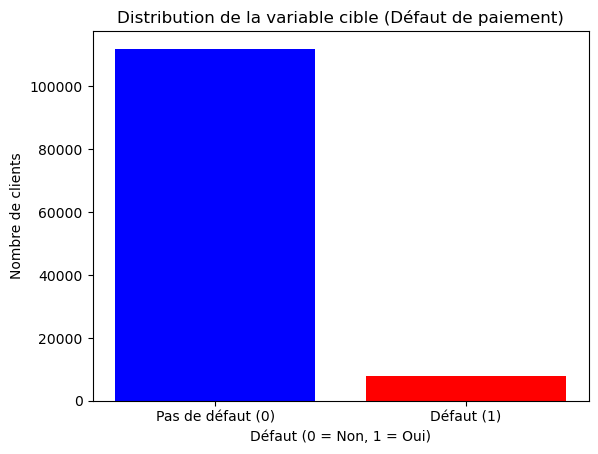

In [74]:
# Calcul manuel des hauteurs des barres
nb_total = len(train["SeriousDlqin2yrs"])
nb_defauts = train["SeriousDlqin2yrs"].sum()
nb_bons = nb_total - nb_defauts

# On trace le graphique en passant directement les positions [0, 1] et les hauteurs [nb_bons, nb_defauts]
plt.bar([0, 1], [nb_bons, nb_defauts], color=['blue', 'red'])
plt.title("Distribution de la variable cible (Défaut de paiement)")
plt.xlabel("Défaut (0 = Non, 1 = Oui)")
plt.ylabel("Nombre de clients")
plt.xticks([0, 1], ["Pas de défaut (0)", "Défaut (1)"])
plt.show()

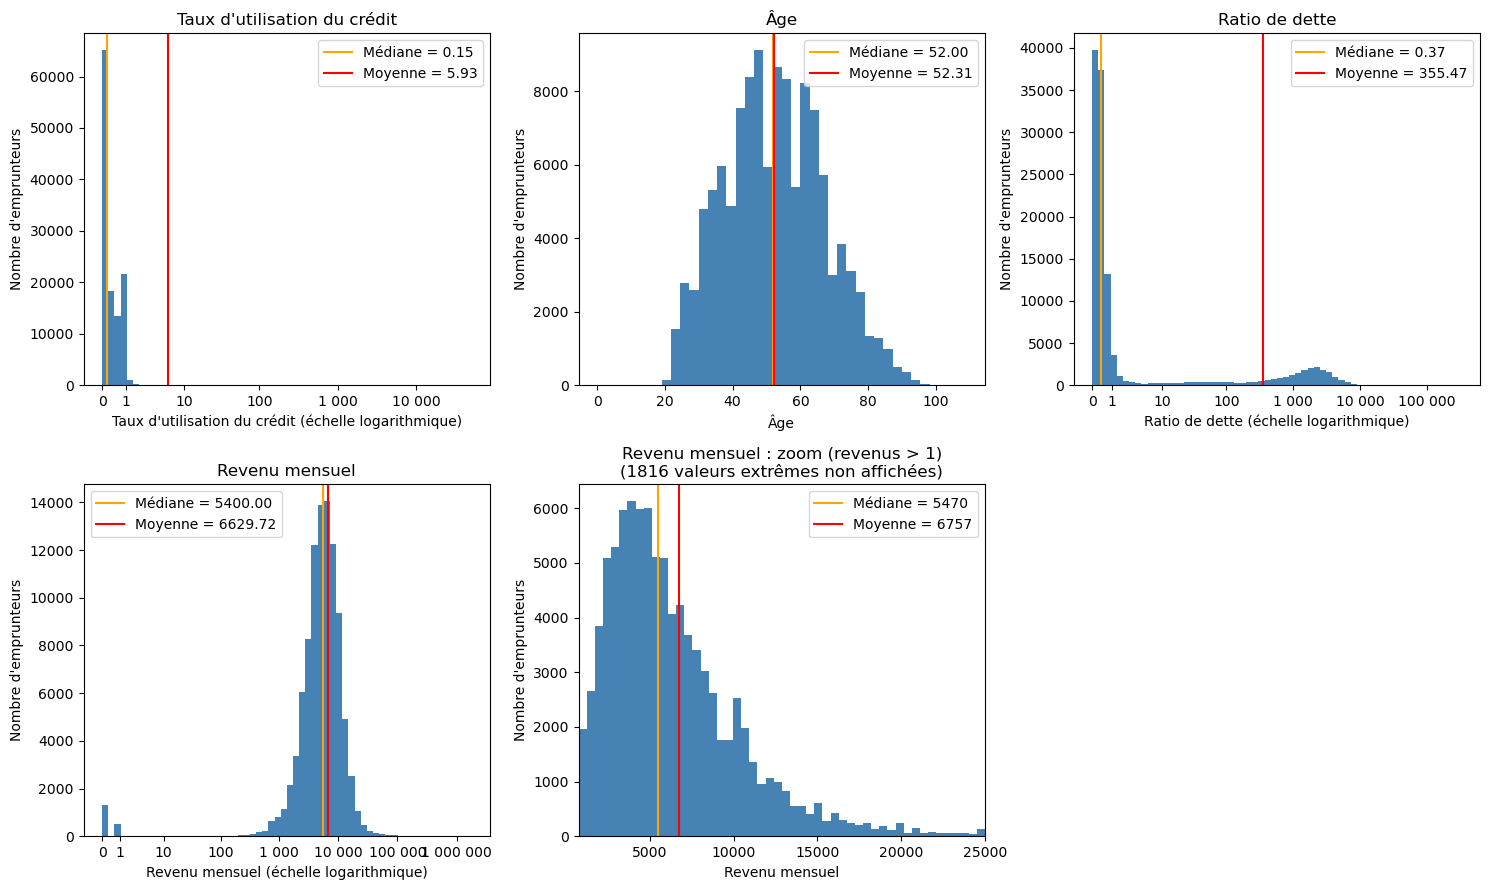

In [ ]:
variables = {
    "RevolvingUtilizationOfUnsecuredLines": "Taux d'utilisation du crédit",
    "age": "Âge",
    "DebtRatio": "Ratio de dette",
    "MonthlyIncome": "Revenu mensuel",
}

variables_log = {"RevolvingUtilizationOfUnsecuredLines","DebtRatio","MonthlyIncome"}

ticks_reels = [0, 1, 10, 100, 1000, 10000, 100000, 1000000]


def regler_axe_log(ax, valeurs, nom):
    """Affiche un axe en log1p mais avec des graduations en valeurs réelles."""
    ticks = [t for t in ticks_reels if t <= valeurs.max()]
    ax.set_xticks(np.log1p(ticks))
    ax.set_xticklabels([f"{t:,}".replace(",", " ") for t in ticks])
    ax.set_xlabel(f"{nom} (échelle logarithmique)")


def tracer_histogramme(ax, serie, nom, log=False, bins=50):
    """Trace un histogramme avec moyenne et médiane."""
    valeurs = serie.dropna()

    moyenne = valeurs.mean()
    mediane = valeurs.median()

    if log:
        valeurs_tracees = np.log1p(valeurs)
        pos_moyenne = np.log1p(moyenne)
        pos_mediane = np.log1p(mediane)

        ax.hist(valeurs_tracees, bins=bins, color="steelblue")
        regler_axe_log(ax, valeurs, nom)
    else:
        valeurs_tracees = valeurs
        pos_moyenne = moyenne
        pos_mediane = mediane

        ax.hist(valeurs_tracees, bins=bins, color="steelblue")
        ax.set_xlabel(nom)

    ax.axvline(pos_mediane, color="orange", label=f"Médiane = {mediane:.2f}")
    ax.axvline(pos_moyenne, color="red", label=f"Moyenne = {moyenne:.2f}")
    ax.set_title(nom)
    ax.set_ylabel("Nombre d'emprunteurs")
    ax.legend()


def tracer_zoom_revenu(ax, serie):
    """Trace un zoom du revenu mensuel en échelle normale."""
    revenus = serie.dropna()
    revenus = revenus[revenus > 1]  # on retire 0 et 1

    moyenne = revenus.mean()
    mediane = revenus.median()

    bas = revenus.quantile(0.01)
    haut = revenus.quantile(0.99)
    nb_exclus = ((revenus < bas) | (revenus > haut)).sum()

    ax.hist(revenus, bins=50, range=(bas, haut), color="steelblue")
    ax.axvline(mediane, color="orange", label=f"Médiane = {mediane:.0f}")
    ax.axvline(moyenne, color="red", label=f"Moyenne = {moyenne:.0f}")

    ax.set_xlim(bas, haut)
    ax.set_title(
        f"Revenu mensuel : zoom (revenus > 1)\n"
        f"({nb_exclus} valeurs extrêmes non affichées)")
    ax.set_xlabel("Revenu mensuel")
    ax.set_ylabel("Nombre d'emprunteurs")
    ax.legend()


# --- Figure ---
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.ravel()

# 4 histogrammes principaux
for ax, (col, nom) in zip(axes[:4], variables.items()):
    tracer_histogramme(ax,train[col],nom,log=(col in variables_log),bins=60 if col in variables_log else 40)

# Zoom sur le revenu
tracer_zoom_revenu(axes[4], train["MonthlyIncome"])

# Dernière case vide
axes[5].axis("off")

plt.tight_layout()
plt.show()

##### Ce qu'on observe

**Ce qui est tracé.** Pour chaque variable, un histogramme (nombre d'emprunteurs par plage de valeurs),
avec la médiane (orange) et la moyenne (rouge). Le taux d'utilisation du crédit, le ratio de dette et le
revenu sont en **échelle logarithmique** : quelques valeurs énormes écraseraient sinon tout le graphique.
Les graduations affichent les vraies valeurs, et chaque pas correspond à une multiplication par 10.

##### Taux d'utilisation du crédit
- **Observation** : la majorité des valeurs est entre 0 et 1. Médiane = […], moyenne = […].
  2 640 lignes dépassent 1.
- **Interprétation** : un taux légèrement supérieur à 1 est possible (dépassement de la limite), mais les
  valeurs énormes sont suspectes. Elles tirent la moyenne bien au-dessus de la médiane.
- **Décision** : plafonner ces valeurs extrêmes dans le pipeline.

##### Âge
- **Observation** : […forme de la distribution, plage principale…]. Une seule ligne avec age < 18.
- **Interprétation** : variable propre, sans valeur extrême problématique.
- **Décision** : rien de particulier, on ignore la ligne aberrante.

##### Ratio de dette
- **Observation** : […]. 27 987 lignes ont un ratio supérieur à 1.
- **Interprétation** : trop de lignes pour de simples erreurs. Hypothèse : le ratio devient énorme quand
  le revenu est manquant, 0 ou 1 (à confirmer avec le tableau croisé).
- **Décision** : à fixer après ce test.

##### Revenu mensuel
- **Observation** : médiane = 5 390, moyenne = 6 651. La majorité des emprunteurs se situe entre
  quelques milliers et 10 000. Deux petites barres isolées, à 0 et à 1.
- **Interprétation** : un revenu de 1 par mois est très suspect, probablement une valeur de remplissage.
  Le zoom (sans log, revenus > 1) montre une distribution asymétrique avec une longue traîne à droite,
  que le log rendait presque symétrique.
- **Décision** : traiter les revenus ≤ 1 comme manquants, avec une colonne « revenu non fiable »
  (19,7 % de manquants au total).

##### Conclusion
Trois variables sont dominées par des valeurs extrêmes ou suspectes. On corrigera cela dans le pipeline
(étape 5), en apprenant les transformations sur le train seulement.

### Les corrélations

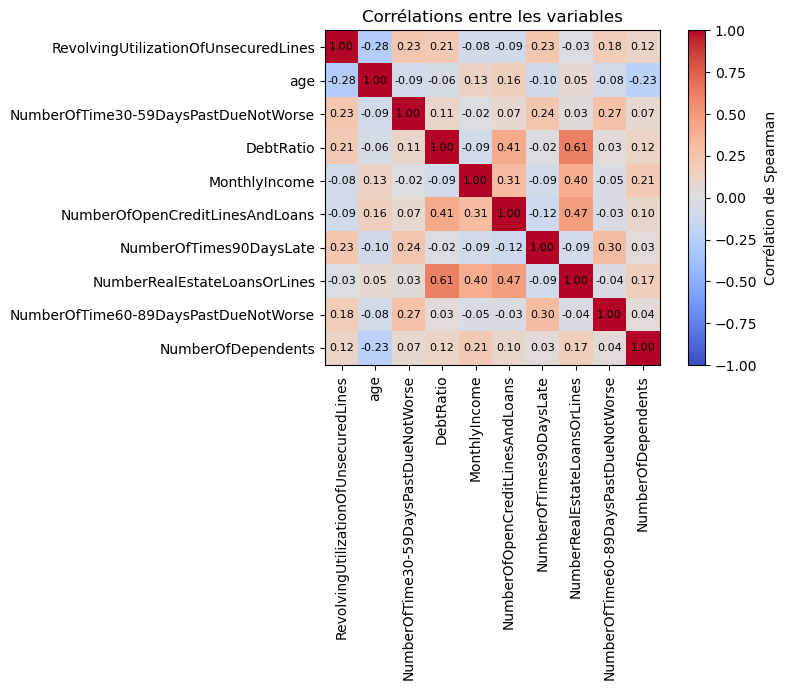

DebtRatio                        NumberRealEstateLoansOrLines       0.61
NumberOfOpenCreditLinesAndLoans  NumberRealEstateLoansOrLines       0.47
DebtRatio                        NumberOfOpenCreditLinesAndLoans    0.41
MonthlyIncome                    NumberRealEstateLoansOrLines       0.40
                                 NumberOfOpenCreditLinesAndLoans    0.31
dtype: float64


In [64]:
correlations = X.corr(method="spearman")      # X = les variables, sans la cible (défini dans la cellule des modèles)


fig, ax = plt.subplots(figsize=(9, 7))
image = ax.imshow(correlations, cmap="coolwarm", vmin=-1, vmax=1)


ax.set_xticks(range(len(correlations.columns)))
ax.set_xticklabels(correlations.columns, rotation=90)
ax.set_yticks(range(len(correlations.columns)))
ax.set_yticklabels(correlations.columns)


# On écrit la valeur de la corrélation dans chaque case
for i in range(len(correlations)):
   for j in range(len(correlations)):
       ax.text(j, i, f"{correlations.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)


fig.colorbar(image, label="Corrélation de Spearman")
ax.set_title("Corrélations entre les variables")
plt.tight_layout()
plt.show()


# Les 5 paires de variables les plus corrélées
paires = correlations.where(np.triu(np.ones(correlations.shape, dtype=bool), k=1)).stack()
paires = paires.reindex(paires.abs().sort_values(ascending=False).index)
print(paires.head(5).round(2))


## 3. Nettoyage des données et baseline

### PREMIERE BASELINE SANS NETTOYAGE

In [123]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, cross_validate
from xgboost import XGBClassifier

# Validation croisée
validation = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Métriques
metriques = ["accuracy","roc_auc","average_precision","f1"]

# Modèles
modeles = {
    "Dummy": DummyClassifier(strategy="most_frequent"),

    "Régression logistique": make_pipeline(
        SimpleImputer(strategy="median", add_indicator=True),
        StandardScaler(),
        LogisticRegression(max_iter=1000)
    ),

    "Random Forest": make_pipeline(
        SimpleImputer(strategy="median", add_indicator=True),
        RandomForestClassifier(
            n_estimators=100,
            random_state=42,
            n_jobs=-1
        )
    ),

    "Gradient Boosting": make_pipeline(
        SimpleImputer(strategy="median", add_indicator=True),
        HistGradientBoostingClassifier(random_state=42)
    ),

    "XGBoost": XGBClassifier(
        n_estimators=300,
        max_depth=3,
        learning_rate=0.05,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=4
    )
}

In [116]:
# On retire seulement deux colonnes techniques : l'identifiant et la colonne de tranches d'âge
X_brut = train.drop(columns=["SeriousDlqin2yrs", "Unnamed: 0", "tranche_age"], errors="ignore")
y_brut = train["SeriousDlqin2yrs"]

modeles_brut = {
    "Modèle naïf": modeles["Dummy"],
    "Régression logistique simple": modeles["Régression logistique"]
}

resultats_brut = {}
for nom, modele in modeles_brut.items():
    scores = cross_validate(modele, X_brut, y_brut, cv=validation, scoring=metriques)
    resultats_brut[nom] = {m: scores[f"test_{m}"].mean() for m in metriques}

print(pd.DataFrame(resultats_brut).T.round(3))

                              accuracy  roc_auc  average_precision     f1
Modèle naïf                      0.933    0.500              0.067  0.000
Régression logistique simple     0.934    0.697              0.230  0.072


### FEATURE ENGINEERING
### PREMIER NETTOYAGE DES DONNEES ET BASELINE

In [117]:
def nettoyer(df):
    df = df.copy()                                            # on travaille sur une copie, pour ne pas toucher à l'original

    colonnes_retards = ["NumberOfTime30-59DaysPastDueNotWorse",
                        "NumberOfTime60-89DaysPastDueNotWorse",
                        "NumberOfTimes90DaysLate"]
    for col in colonnes_retards:
        df.loc[df[col] >= 96, col] = np.nan                   # les codes 96 et 98 sont des valeurs spéciales

    df.loc[df["MonthlyIncome"] <= 1, "MonthlyIncome"] = np.nan   # revenus 0 ou 1 : pas fiables
    df.loc[df["MonthlyIncome"].isna(), "DebtRatio"] = np.nan     # sans revenu fiable, le ratio de dette n'a pas de sens
    df.loc[df["age"] < 18, "age"] = np.nan                    # âge impossible

    return df.drop(columns=["Unnamed: 0", "tranche_age"], errors="ignore")   # on retire l'identifiant et la colonne de tranches d'âge


train_propre = nettoyer(train)

# Vérifications
print(train_propre.isna().sum())

avant = train["DebtRatio"]
apres = train_propre["DebtRatio"]
print(f"\nDebtRatio avant : moyenne = {avant.mean():.2f}, médiane = {avant.median():.2f}, lignes > 1 : {(avant > 1).sum()}")
print(f"DebtRatio après : moyenne = {apres.mean():.2f}, médiane = {apres.median():.2f}, lignes > 1 : {(apres > 1).sum()}")

RevolvingUtilizationOfUnsecuredLines        0
age                                         1
NumberOfTime30-59DaysPastDueNotWorse      218
DebtRatio                               25590
MonthlyIncome                           25590
NumberOfOpenCreditLinesAndLoans             0
NumberOfTimes90DaysLate                   218
NumberRealEstateLoansOrLines                0
NumberOfTime60-89DaysPastDueNotWorse      218
NumberOfDependents                       3123
SeriousDlqin2yrs                            0
dtype: int64

DebtRatio avant : moyenne = 355.47, médiane = 0.37, lignes > 1 : 28159
DebtRatio après : moyenne = 0.41, médiane = 0.29, lignes > 1 : 4147


### Les données nettoyées : ...

In [124]:
X = train_propre.drop(columns=["SeriousDlqin2yrs"])     # les variables
y = train_propre["SeriousDlqin2yrs"]                    # la cible (défaut ou non)

modeles_avec_nettoyage = {
    "Modèle naïf": modeles["Dummy"],
    "Régression logistique simple": modeles["Régression logistique"]
}

resultats = {}
for nom, modele in modeles_avec_nettoyage.items():
    scores = cross_validate(modele, X, y, cv=validation, scoring=metriques)
    resultats[nom] = {m: scores[f"test_{m}"].mean() for m in metriques}

print(pd.DataFrame(resultats).T.round(3))

                              accuracy  roc_auc  average_precision     f1
Modèle naïf                      0.933    0.500              0.067  0.000
Régression logistique simple     0.936    0.814              0.348  0.241


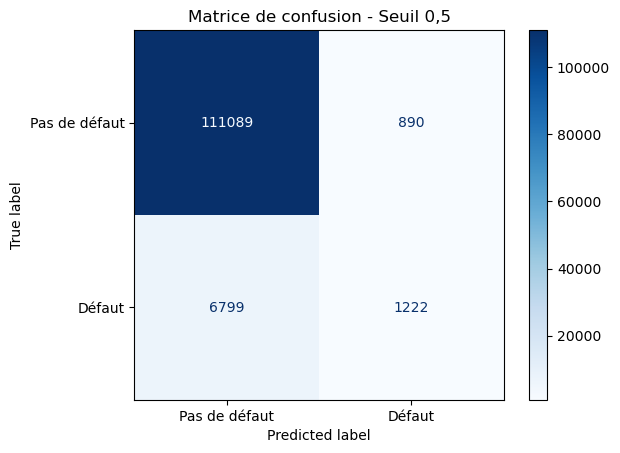

In [119]:
from sklearn.metrics import ConfusionMatrixDisplay

predictions = (probas >= 0.5).astype(int)

ConfusionMatrixDisplay.from_predictions(
    y,
    predictions,
    display_labels=["Pas de défaut", "Défaut"],
    cmap="Blues"
)

plt.title("Matrice de confusion - Seuil 0,5")
plt.show()

### Les variables d'intérêt

In [120]:
from sklearn.metrics import roc_auc_score

force = {}
for col in X.columns:
    score = X[col].fillna(X[col].median())       # les manquants sont remplacés par la médiane, pour ce calcul seulement
    auc = roc_auc_score(y, score)
    force[col] = max(auc, 1 - auc)               # si auc < 0.5, la variable agit en sens inverse : on la retourne

print(pd.Series(force).sort_values(ascending=False).round(3))

RevolvingUtilizationOfUnsecuredLines    0.777
NumberOfTime30-59DaysPastDueNotWorse    0.679
NumberOfTimes90DaysLate                 0.650
age                                     0.635
NumberOfTime60-89DaysPastDueNotWorse    0.614
MonthlyIncome                           0.578
DebtRatio                               0.558
NumberOfOpenCreditLinesAndLoans         0.545
NumberOfDependents                      0.545
NumberRealEstateLoansOrLines            0.539
dtype: float64


commentaire :
- Les premières variables importantes pour décrire, on voit un intérêt d'en combiner certaines car le modèle a une meilleure perf que elles séparées
- debtratio notament presque variable inutile on dirait alors que cela relève + de l'anomalie que d'une variable inutile

### Comparaison de modèles
##### Premier test sans le feature engineering

In [128]:
X = train_propre.drop(columns=["SeriousDlqin2yrs"])     # les variables
y = train_propre["SeriousDlqin2yrs"]                    # la cible (défaut ou non)

modeles_avec_features = {
    "Modèle naïf": modeles["Dummy"],
    "Régression logistique simple": modeles["Régression logistique"],
    "Forêt aléatoire": modeles["Random Forest"],
    "GB": modeles["Gradient Boosting"]
}

resultats = {}
for nom, modele in modeles_avec_features.items():
    scores = cross_validate(modele, X, y, cv=validation, scoring=metriques)
    resultats[nom] = {m: scores[f"test_{m}"].mean() for m in metriques}

# On rajoute le modèle XGBoost
scores = cross_validate(modeles["XGBoost"], X, y, cv=validation, scoring=metriques)
resultats["XGBoost"] = {m: scores[f"test_{m}"].mean() for m in metriques}

print(pd.DataFrame(resultats).T.round(3))

                              accuracy  roc_auc  average_precision     f1
Modèle naïf                      0.933    0.500              0.067  0.000
Régression logistique simple     0.936    0.814              0.348  0.241
Forêt aléatoire                  0.935    0.833              0.342  0.266
GB                               0.937    0.862              0.387  0.271
XGBoost                          0.937    0.863              0.392  0.280


In [129]:
def ajouter_retards(df):
    df = df.copy()

    colonnes = [
        "NumberOfTime30-59DaysPastDueNotWorse",
        "NumberOfTime60-89DaysPastDueNotWorse",
        "NumberOfTimes90DaysLate"
    ]

    df["TotalLatePayments"] = df[colonnes].sum(axis=1, min_count=3)

    return df

In [130]:
# version 1 de base
V1 = train_propre.copy()
# version 2 avec les retards
V2 = ajouter_retards(V1)

datasets = {
    "V1 : Nettoyage simple": nettoyer(train),
    "V2 : Total des retards": ajouter_retards(nettoyer(train))
}

### Test avec le feature ingineering

In [131]:
resultats = []

for nom_dataset, df in datasets.items():

    X = df.drop(columns=["SeriousDlqin2yrs"])
    y = df["SeriousDlqin2yrs"]

    for nom_modele, modele in modeles.items():

        scores = cross_validate(
            modele,
            X,
            y,
            cv=validation,
            scoring=metriques
        )

        resultats.append({
            "Dataset": nom_dataset,
            "Modèle": nom_modele,
            "Accuracy": scores["test_accuracy"].mean(),
            "ROC-AUC": scores["test_roc_auc"].mean(),
            "Average Precision": scores["test_average_precision"].mean()
        })

resultats_df = pd.DataFrame(resultats)

print(resultats_df.round(3))

                  Dataset                 Modèle  Accuracy  ROC-AUC  \
0   V1 : Nettoyage simple                  Dummy     0.933    0.500   
1   V1 : Nettoyage simple  Régression logistique     0.936    0.814   
2   V1 : Nettoyage simple          Random Forest     0.935    0.833   
3   V1 : Nettoyage simple      Gradient Boosting     0.937    0.862   
4   V1 : Nettoyage simple                XGBoost     0.937    0.863   
5  V2 : Total des retards                  Dummy     0.933    0.500   
6  V2 : Total des retards  Régression logistique     0.936    0.814   
7  V2 : Total des retards          Random Forest     0.935    0.833   
8  V2 : Total des retards      Gradient Boosting     0.937    0.862   
9  V2 : Total des retards                XGBoost     0.937    0.863   

   Average Precision  
0              0.067  
1              0.348  
2              0.342  
3              0.387  
4              0.392  
5              0.067  
6              0.348  
7              0.342  
8          

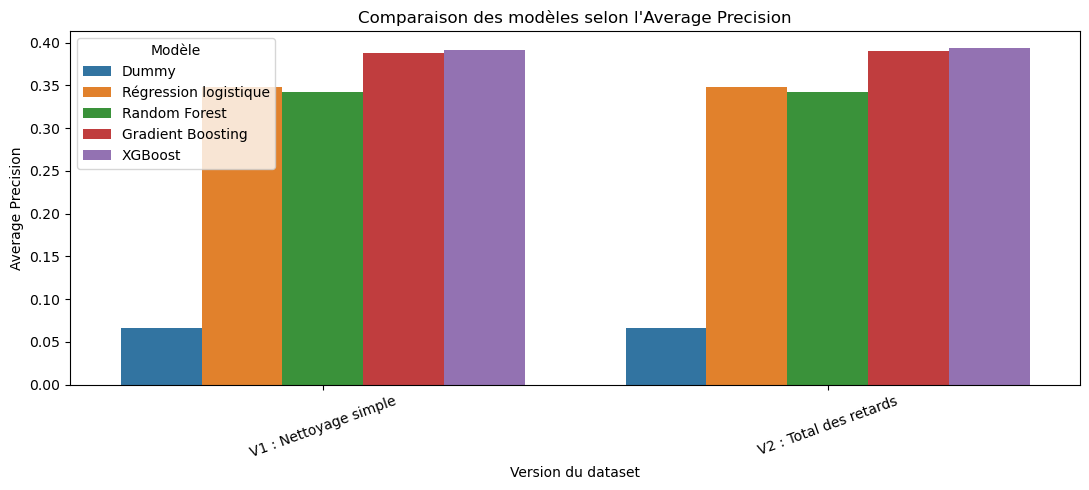

In [132]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 5))

sns.barplot(
    data=resultats_df,
    x="Dataset",
    y="Average Precision",
    hue="Modèle"
)

plt.title("Comparaison des modèles selon l'Average Precision")
plt.xlabel("Version du dataset")
plt.ylabel("Average Precision")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

# Optimisation

In [134]:
df = datasets["V2 : Total des retards"]

X = df.drop(columns=["SeriousDlqin2yrs"])
y = df["SeriousDlqin2yrs"]

In [135]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.base import clone

# Modèle XGBoost défini précédemment
xgb = clone(modeles["XGBoost"])
xgb.set_params(n_jobs=2, tree_method="hist")

# Paramètres à explorer
parametres = {
    "n_estimators": [200, 400, 600],
    "max_depth": [2, 3, 4, 5],
    "learning_rate": [0.01, 0.03, 0.05, 0.1],
    "subsample": [0.7, 0.85, 1.0],
    "colsample_bytree": [0.7, 0.85, 1.0]
}

# Recherche aléatoire avec validation croisée
recherche_xgb = RandomizedSearchCV(
    estimator=xgb,
    param_distributions=parametres,
    n_iter=20,
    scoring="average_precision",
    cv=validation,
    random_state=42,
    n_jobs=2,
    verbose=1
)

recherche_xgb.fit(X, y)

print("Meilleurs paramètres :")
print(recherche_xgb.best_params_)

print("\nMeilleure Average Precision :")
print(round(recherche_xgb.best_score_, 4))

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Meilleurs paramètres :
{'subsample': 0.85, 'n_estimators': 200, 'max_depth': 4, 'learning_rate': 0.03, 'colsample_bytree': 0.85}

Meilleure Average Precision :
0.3952


In [136]:
resultats_optimisation = pd.DataFrame(recherche_xgb.cv_results_)

colonnes = [
    "param_n_estimators",
    "param_max_depth",
    "param_learning_rate",
    "param_subsample",
    "param_colsample_bytree",
    "mean_test_score",
    "std_test_score"
]

display(
    resultats_optimisation[colonnes]
    .sort_values("mean_test_score", ascending=False)
    .head(10)
    .round(4)
)

,param_n_estimators,param_max_depth,param_learning_rate,param_subsample,param_colsample_bytree,mean_test_score,std_test_score
12,200,4,0.03,0.85,0.85,0.3952,0.0053
3,400,5,0.01,0.70,0.70,0.3948,0.0049
8,600,3,0.03,0.70,0.85,0.3943,0.0056
13,200,3,0.03,0.85,1.00,0.3939,0.0064
1,400,2,0.05,0.70,0.70,0.3936,0.0063
14,400,2,0.03,0.70,0.70,0.3930,0.0072
15,200,5,0.01,1.00,0.85,0.3924,0.0050
16,400,4,0.05,0.85,1.00,0.3923,0.0053
17,200,2,0.05,0.70,0.70,0.3922,0.0071
11,600,5,0.03,0.85,0.70,0.3901,0.0047


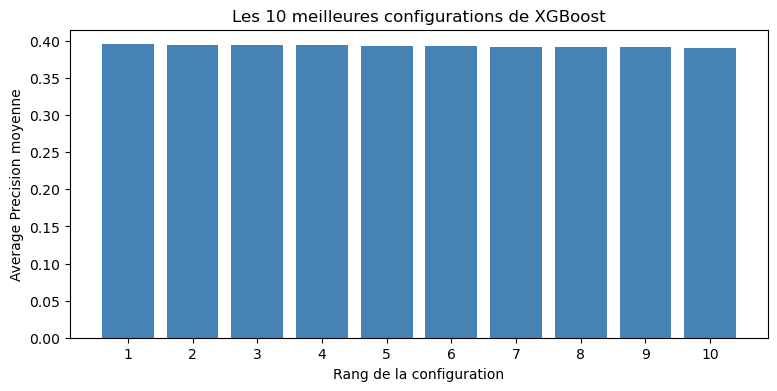

In [137]:
resultats_optimisation = resultats_optimisation.sort_values(
    "mean_test_score", ascending=False
).head(10)

plt.figure(figsize=(9, 4))

plt.bar(
    range(1, 11),
    resultats_optimisation["mean_test_score"],
    color="steelblue"
)

plt.xlabel("Rang de la configuration")
plt.ylabel("Average Precision moyenne")
plt.title("Les 10 meilleures configurations de XGBoost")
plt.xticks(range(1, 11))
plt.show()